# 04 — Forecast evaluation, robustness and volatility targeting

This notebook consolidates the loss comparisons, VIX ablation, market-regime analysis, data-vintage diagnostics and portfolio risk illustration. The final test sample is historical and is not used for model selection.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd()
while not (ROOT / 'outputs' / 'forecast_metrics.csv').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / 'outputs'
metrics = pd.read_csv(OUT / 'forecast_metrics.csv')
dm = pd.read_csv(OUT / 'dm_tests_vs_garch.csv')
ablation = pd.read_csv(OUT / 'vix_ablation_dm_tests.csv')
regimes = pd.read_csv(OUT / 'forecast_metrics_by_vix_regime.csv')
vintages = pd.read_csv(OUT / 'forecast_metrics_by_data_vintage.csv')
vintage_diffs = pd.read_csv(OUT / 'data_vintage_comparison.csv')
portfolio = pd.read_csv(OUT / 'volatility_target_metrics_sensitivity.csv')

In [2]:
print('HAC-adjusted comparisons against GARCH(1,1) that remain significant after Holm correction:')
display(dm[dm.reject_5pct_holm_global == True][['horizon','model','mean_loss_diff_a_minus_b','dm_stat','p_value_holm_global']])
print('Matched VIX ablation comparisons:')
display(ablation[['horizon','model_with_VIX','model_without_VIX','mean_loss_diff_a_minus_b','p_value_holm_global','reject_5pct_holm_global']])

HAC-adjusted comparisons against GARCH(1,1) that remain significant after Holm correction:


,horizon,model,mean_loss_diff_a_minus_b,dm_stat,p_value_holm_global
1,1,EWMA_0.94,0.045990,2.997943,4.620749e-02
2,1,GJR_GARCH_1_1,-0.045855,-3.022269,4.515979e-02
4,1,HAR_RV_with_VIX,-0.103939,-5.848862,1.336360e-07
5,1,HistoricalVol_22d,0.091201,4.208801,6.161502e-04
6,1,LSTM,-0.071385,-3.296755,2.053988e-02
13,5,HAR_RV_with_VIX,-0.077873,-5.622883,4.882699e-07
14,5,HistoricalVol_22d,0.111167,3.811667,3.036715e-03
15,5,LSTM,-0.060142,-3.228144,2.367328e-02
16,5,XGBoost_no_VIX,-0.055267,-4.151485,7.597482e-04
17,5,XGBoost_with_VIX,-0.082967,-4.553433,1.319438e-04


Matched VIX ablation comparisons:


,horizon,model_with_VIX,model_without_VIX,mean_loss_diff_a_minus_b,p_value_holm_global,reject_5pct_holm_global
0,1,HAR_RV_with_VIX,HAR_RV_no_VIX,-0.126043,0.000001,True
1,1,XGBoost_with_VIX,XGBoost_no_VIX,-0.009779,0.561008,False
2,5,HAR_RV_with_VIX,HAR_RV_no_VIX,-0.104134,0.000005,True
3,5,XGBoost_with_VIX,XGBoost_no_VIX,-0.027700,0.086792,False
4,21,HAR_RV_with_VIX,HAR_RV_no_VIX,-0.065956,0.086792,False
5,21,XGBoost_with_VIX,XGBoost_no_VIX,-0.040326,0.385375,False


In [3]:
print('Top QLIKE model by horizon and VIX regime:')
for regime in regimes.vix_regime.unique():
    print(regime)
    display(regimes[regimes.vix_regime == regime].sort_values(['horizon','qlike']).groupby('horizon').head(1)[['horizon','model','n','qlike','mean_realised_vol']])
print('Data-vintage return comparison:')
display(vintage_diffs[vintage_diffs.variable.isin(['market_return','market_excess','rf'])])

Top QLIKE model by horizon and VIX regime:
high_vix


,horizon,model,n,qlike,mean_realised_vol
0,1,HAR_RV_with_VIX,430,-1.505683,0.243840
10,5,XGBoost_with_VIX,430,-1.527218,0.278608
20,21,GJR_GARCH_1_1,430,-1.562840,0.259214


normal_vix


,horizon,model,n,qlike,mean_realised_vol
30,1,HAR_RV_with_VIX,2018,-3.220839,0.097035
40,5,XGBoost_with_VIX,2014,-3.121989,0.120427
50,21,XGBoost_with_VIX,1998,-2.776579,0.135547


Data-vintage return comparison:


,variable,n_common,overlap_start,overlap_end,correlation_ciz_vs_fiz,mean_absolute_difference,max_absolute_difference,mean_difference_ciz_minus_fiz,period
0,market_return,8817,1990-01-02,2024-12-31,0.999982,0.000041,0.00080,9.889985e-07,full_common_history
1,market_excess,8817,1990-01-02,2024-12-31,0.999984,0.000027,0.00080,1.871385e-06,full_common_history
2,rf,8817,1990-01-02,2024-12-31,0.967875,0.000017,0.00005,-8.823863e-07,full_common_history
7,market_return,2012,2017-01-03,2024-12-31,0.999974,0.000056,0.00080,6.426441e-06,test_period_common_dates
8,market_excess,2012,2017-01-03,2024-12-31,0.999976,0.000043,0.00080,3.876740e-06,test_period_common_dates
9,rf,2012,2017-01-03,2024-12-31,0.958281,0.000017,0.00005,2.549702e-06,test_period_common_dates


,strategy,cagr,annualised_volatility,sharpe,max_drawdown,average_exposure
43,GARCH_1_1_target10_cost5bps,0.098562,0.097448,0.755255,-0.144675,0.689940
46,HAR_RV_with_VIX_target10_cost5bps,0.094553,0.092170,0.753366,-0.144185,0.679803
48,LSTM_target10_cost5bps,0.090099,0.093527,0.700170,-0.148651,0.664016
50,XGBoost_with_VIX_target10_cost5bps,0.089175,0.086312,0.741345,-0.128479,0.625664


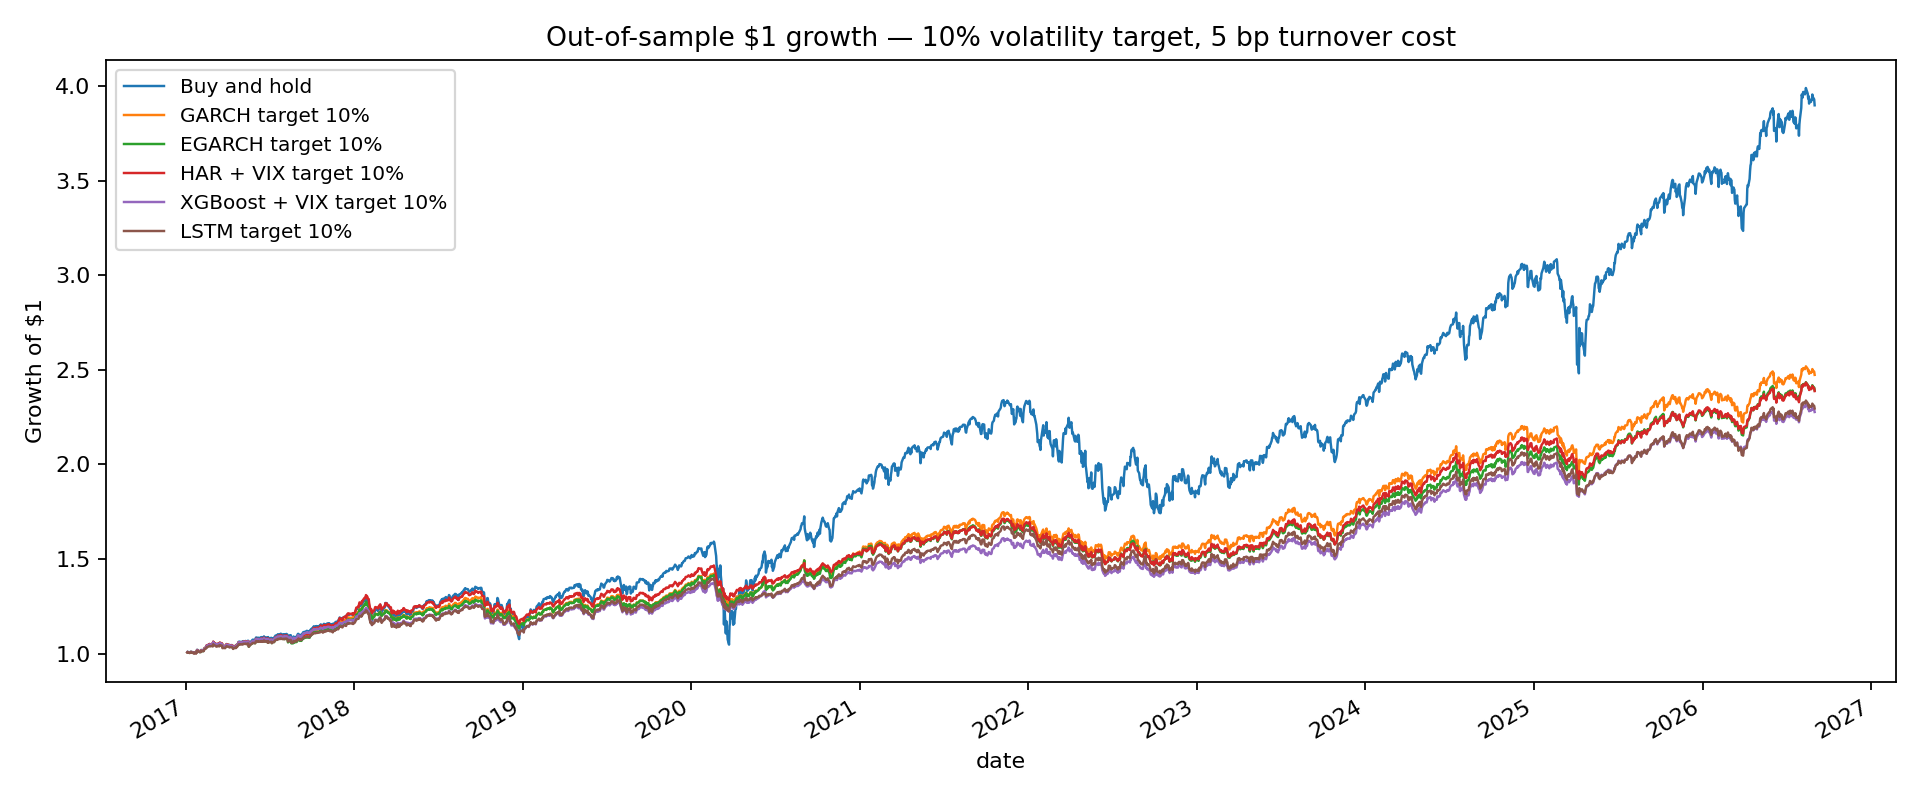

In [4]:
# Main portfolio illustration: 10% target volatility and 5 bp turnover cost.
portfolio_view = portfolio[(portfolio.target_volatility == 0.10) & (portfolio.cost_bps == 5)].copy()
portfolio_view = portfolio_view[portfolio_view.strategy.isin(['BuyAndHold','GARCH_1_1_target10_cost5bps','HAR_RV_with_VIX_target10_cost5bps','XGBoost_with_VIX_target10_cost5bps','LSTM_target10_cost5bps'])]
display(portfolio_view[['strategy','cagr','annualised_volatility','sharpe','max_drawdown','average_exposure']])
fig_path = OUT / 'figures' / 'volatility_target_equity_curves.png'
if fig_path.exists():
    display(Image(filename=str(fig_path)))

## Interpretation safeguards

- HAC/DM-style p-values compare average forecast losses; they do not establish economic value or future persistence.
- A high-VIX threshold is estimated from training data only. Regime sample sizes differ and regime rankings are descriptive.
- CIZ/FIZ differences include both the publisher's data-vintage/return-construction differences and the documented `RF` source change. The comparison is not a causal identification exercise.
- Volatility targeting is a long-only exposure-scaling demonstration. The lower realised volatility and drawdown are obtained partly by holding less market exposure and therefore come with lower CAGR; this is not evidence of alpha.
- VIX is an S&P 500 option-implied measure, whereas the return target is a broad US market proxy.